## Trace driven simulation
### The first part is indoor trace driven simulation

In [2]:
# read complex data from .dat file
from tracemalloc import stop
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from read_raw_data import read_dat_file 

iq0_path = '/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx0.dat'
iq1_path = '/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx1.dat'
iq2_path = '/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx2.dat'

# we have 3 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB0 |       W + E
# | LNB1      |         S
#  ------------

start_idx = int(1e5)
stop_idx = int(1e6)
iq0 =  read_dat_file(iq0_path, start_idx, stop_idx)
iq1 = read_dat_file(iq1_path, start_idx, stop_idx)
iq2 = read_dat_file(iq2_path, start_idx, stop_idx)

# converting to received signal format 
received_sig = np.zeros((3,len(iq0)), dtype=complex)
received_sig[0] = iq0   
received_sig[1] = iq1
received_sig[2] = iq2
print("Received signal shape", received_sig.shape)

Received signal shape (3, 900000)


In [3]:
from random import sample


c = 3e8
fc = 11e9
lam = c/fc
d0 = 0.20 # vertical distance between LNB0 and LNB2
d1 = 0.135 # horizontal distance between LNB0 and LNB1
sample_rate = 2e6

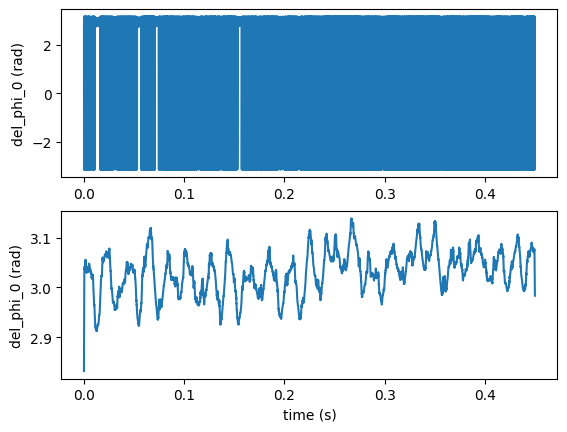

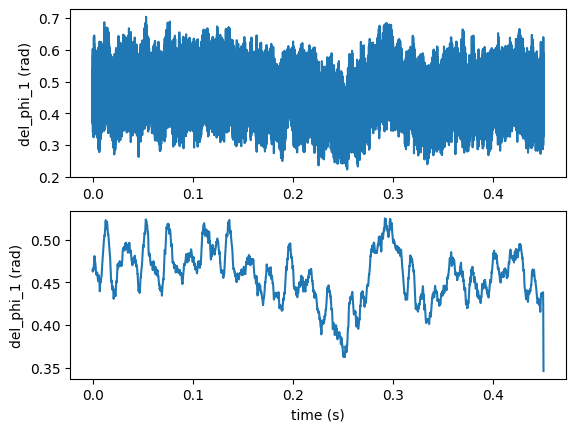

/home/ishani/miniconda3/envs/starloc/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


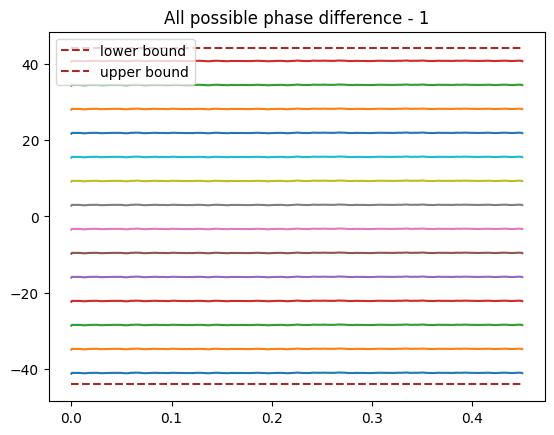

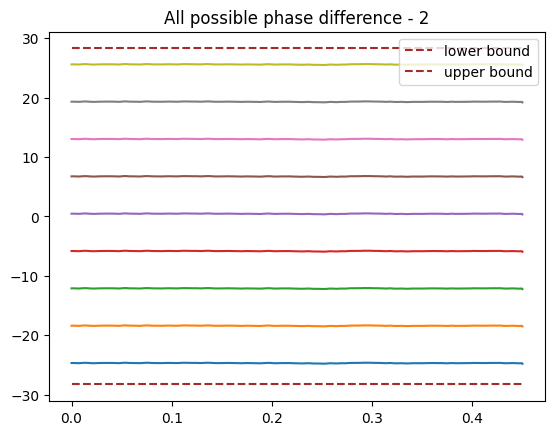

In [4]:
vertical_ambiguity = int(d0/(lam/2))
horizontal_ambiguity = int(d1/(lam/2))
num_ambiguity = vertical_ambiguity*horizontal_ambiguity

del_phi_0 = np.zeros((vertical_ambiguity, received_sig.shape[1]))
del_phi_1 = np.zeros((horizontal_ambiguity, received_sig.shape[1]))
pattern_0 = np.unwrap(np.angle(received_sig[1,:]/received_sig[2,:]))
pattern_1 = np.unwrap(np.angle(received_sig[2,:]/received_sig[0,:]))
vertical_phi_bound = np.pi*vertical_ambiguity
horizontal_phi_bound = np.pi*horizontal_ambiguity

# low pass filter for average ever 1000 samples
pattern_0 = signal.filtfilt([1/1000]*1000, 1, pattern_0)
pattern_1 = signal.filtfilt([1/1000]*1000, 1, pattern_1)
t_list = np.linspace(0, received_sig.shape[1]/sample_rate, received_sig.shape[1])

plt.figure()
plt.subplot(2,1,1)
plt.plot(t_list, np.angle(received_sig[1,:]/received_sig[2,:]))
plt.ylabel('del_phi_0 (rad)')
plt.subplot(2,1,2)
plt.plot(t_list, pattern_0)
plt.xlabel('time (s)')
plt.ylabel('del_phi_0 (rad)')
plt.show()

plt.figure()
plt.subplot(2,1,1)
plt.plot(t_list, np.angle(received_sig[2,:]/received_sig[0,:]))
plt.ylabel('del_phi_1 (rad)')
plt.subplot(2,1,2)
plt.plot(t_list, pattern_1)
plt.xlabel('time (s)')
plt.ylabel('del_phi_1 (rad)')
plt.show()

# calculate all possible delta_phis
for i in range(vertical_ambiguity):
    del_phi_0[i, :] = pattern_0 + 2*np.pi*(i-vertical_ambiguity//2)
if pattern_0[0] < 0:
    del_phi_0 = del_phi_0 + 2*np.pi

plt.figure()
for i in range(vertical_ambiguity):
    plt.plot(t_list, del_phi_0[i, :])

plt.hlines(-vertical_phi_bound, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='lower bound')
plt.hlines(vertical_phi_bound, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='upper bound')
plt.legend()
plt.title('All possible phase difference - 1')
plt.show()

for i in range(horizontal_ambiguity):
    del_phi_1[i, :] = pattern_1 + 2*np.pi*(i-horizontal_ambiguity//2)
if pattern_1[0] < 0:
    del_phi_1 = del_phi_1 + 2*np.pi
plt.figure()
for i in range(horizontal_ambiguity):
    plt.plot(t_list, del_phi_1[i, :])
plt.hlines(-horizontal_phi_bound, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='lower bound')
plt.hlines(horizontal_phi_bound, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='upper bound')
plt.legend()
plt.title('All possible phase difference - 2')
plt.show()


Number of del_phi_0 ambiguities: 14
Number of del_phi_1 ambiguities: 9


Text(0, 0.5, 'Elevation (deg)')

<Figure size 640x480 with 0 Axes>

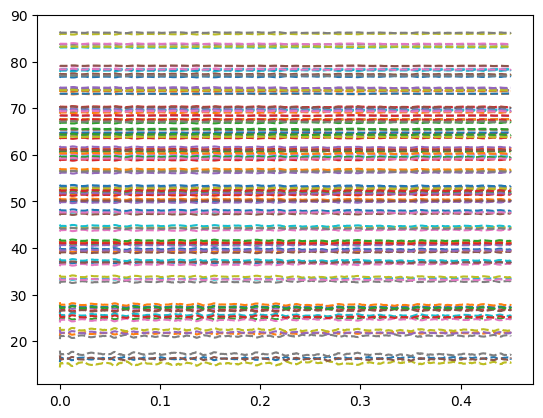

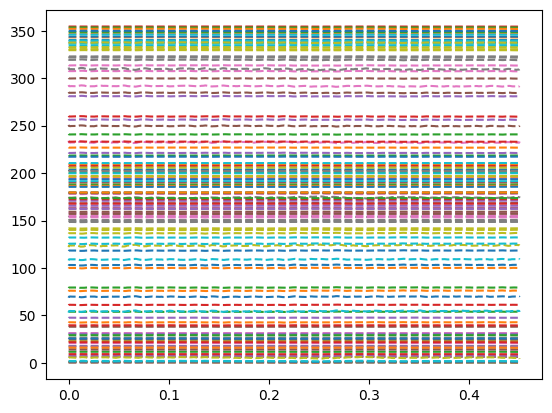

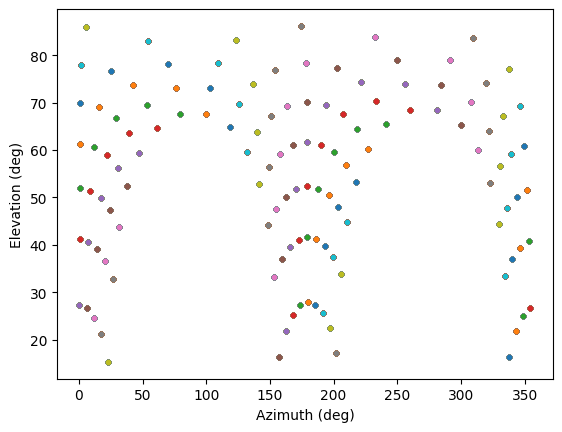

In [43]:
# calculate AoA
# first check which del_phi exceeds the bounds, exclude those
del_phi_0_valid_idx = (np.max(del_phi_0, axis=1) < vertical_phi_bound) & (np.min(del_phi_0, axis=1) > -vertical_phi_bound)
del_phi_1_valid_idx = (np.max(del_phi_1, axis=1) < horizontal_phi_bound) & (np.min(del_phi_1, axis=1) > -horizontal_phi_bound)
del_phi_0_valid = del_phi_0[del_phi_0_valid_idx, :]
del_phi_1_valid = del_phi_1[del_phi_1_valid_idx, :]
num_ambiguity_2d = len(del_phi_0_valid) * len(del_phi_1_valid)
print('Number of del_phi_0 ambiguities: '+str(len(del_phi_0_valid)))
print('Number of del_phi_1 ambiguities: '+str(len(del_phi_1_valid)))

# then do the formula based AoA estimation
plt.figure()
phi, az, el = np.zeros((num_ambiguity_2d, len(t_list))), np.zeros((num_ambiguity_2d, len(t_list))), np.zeros((num_ambiguity_2d, len(t_list)))
for i in range(len(del_phi_0_valid)):
    for j in range(len(del_phi_1_valid)):

        phi_ = np.arctan2(-d1*del_phi_1_valid[j, :], -d0*del_phi_0_valid[i, :])
        phi_ = np.mod(phi_, 2*np.pi)
        az_ = 2*np.pi-phi_
        
        # elevation
        el_ = np.arccos(-del_phi_0_valid[i, :]*lam/(2*np.pi*d0*np.cos(az_)))
        az[i*len(del_phi_1_valid)+j, :] = az_
        el[i*len(del_phi_1_valid)+j, :] = el_

plt.figure()
for i in range(num_ambiguity_2d):
    plt.plot(t_list, np.rad2deg(el[i, :]), linestyle='dashed', label='ambiguity '+str(i))
# plt.plot(t_list, el_gt, label='ground truth')
# plt.legend()
plt.figure()
for i in range(num_ambiguity_2d):
    plt.plot(t_list, np.rad2deg(az[i, :]), linestyle='dashed', label='ambiguity '+str(i))
# plt.plot(t_list, az_gt, label='ground truth')
# plt.legend()
plt.figure()
for i in range(num_ambiguity_2d):
    for i in range(num_ambiguity_2d):
        plt.plot(np.mean(np.rad2deg(az[i, :])), np.mean(np.rad2deg(el[i, :])),'.')
plt.xlabel('Azimuth (deg)')
plt.ylabel('Elevation (deg)')

In [ ]:
'''
# just worked out with different angles (complementary ones) assumed as az and el
# calculate AoA
# first check which del_phi exceeds the bounds, exclude those
del_phi_0_valid_idx = (np.max(del_phi_0, axis=1) < vertical_phi_bound) & (np.min(del_phi_0, axis=1) > -vertical_phi_bound)
del_phi_1_valid_idx = (np.max(del_phi_1, axis=1) < horizontal_phi_bound) & (np.min(del_phi_1, axis=1) > -horizontal_phi_bound)
del_phi_0_valid = del_phi_0[del_phi_0_valid_idx, :]
del_phi_1_valid = del_phi_1[del_phi_1_valid_idx, :]
num_ambiguity_2d = len(del_phi_0_valid) * len(del_phi_1_valid)
print('Number of del_phi_0 ambiguities: '+str(len(del_phi_0_valid)))
print('Number of del_phi_1 ambiguities: '+str(len(del_phi_1_valid)))

# then do the formula based AoA estimation
plt.figure()
phi, az, el = np.zeros((num_ambiguity_2d, len(t_list))), np.zeros((num_ambiguity_2d, len(t_list))), np.zeros((num_ambiguity_2d, len(t_list)))
for i in range(len(del_phi_0_valid)):
    for j in range(len(del_phi_1_valid)):
        phi_ = np.arctan2(-d0*del_phi_0_valid[i, :], d1*del_phi_1_valid[j, :])
        phi_ = np.mod(phi_, 2*np.pi)
        az_ = np.mod(phi_+np.pi/2, 2*np.pi)        
        el_ = np.arccos(-del_phi_0_valid[i, :]*lam/(2*np.pi*d0*np.sin(phi_)))

        az[i*len(del_phi_1_valid)+j, :] = az_
        el[i*len(del_phi_1_valid)+j, :] = el_

plt.figure()
for i in range(num_ambiguity_2d):
    plt.plot(t_list, np.rad2deg(el[i, :]), linestyle='dashed', label='ambiguity '+str(i))
# plt.plot(t_list, el_gt, label='ground truth')
# plt.legend()
plt.figure()
for i in range(num_ambiguity_2d):
    plt.plot(t_list, np.rad2deg(az[i, :]), linestyle='dashed', label='ambiguity '+str(i))
# plt.plot(t_list, az_gt, label='ground truth')
# plt.legend()

# Plot az el on same graph. 
# We can take mean value of az[i,:] and el[i,:] here since antenna is not moving
plt.figure()
for i in range(num_ambiguity_2d):
    for i in range(num_ambiguity_2d):
        plt.plot(np.mean(np.rad2deg(az[i, :])), np.mean(np.rad2deg(el[i, :])),'.')
plt.xlabel('Azimuth (deg)')
plt.ylabel('Elevation (deg)')
'''

Trace driven simulation with corrected initial phase offset

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from read_raw_data import read_dat_file 

iq0_path = '/home/ishani/LeoPNT/USRP_data/12_27_onlyref/time_20_47_freq_11_325G_bw_2.0M_1703720429.3571067_inrx0.dat'
iq1_path = '/home/ishani/LeoPNT/USRP_data/12_27_onlyref/time_20_47_freq_11_325G_bw_2.0M_1703720429.3571067_inrx1.dat'
iq2_path = '/home/ishani/LeoPNT/USRP_data/12_27_onlyref/time_20_47_freq_11_325G_bw_2.0M_1703720429.3571067_inrx2.dat'

# we have 3 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB1 |       W + E
# | LNB0      |         S
#  ------------

start_idx = None
stop_idx = None
iq0 =  read_dat_file(iq0_path, start_idx, stop_idx)
iq1 = read_dat_file(iq1_path, start_idx, stop_idx)
iq2 = read_dat_file(iq2_path, start_idx, stop_idx)

print(len(iq0), len(iq1), len(iq2))
# converting to received signal format 
received_sig = np.zeros((3,len(iq0)), dtype=complex)
received_sig[0] = iq0   
received_sig[1] = iq1
received_sig[2] = iq2
print("Received signal shape", received_sig.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/home/ishani/LeoPNT/USRP_data/12_27_/time_20_47_freq_11_325G_bw_2.0M_1703720429.3571067_inrx0.dat'

(-3.141592653589793, 3.141592653589793)

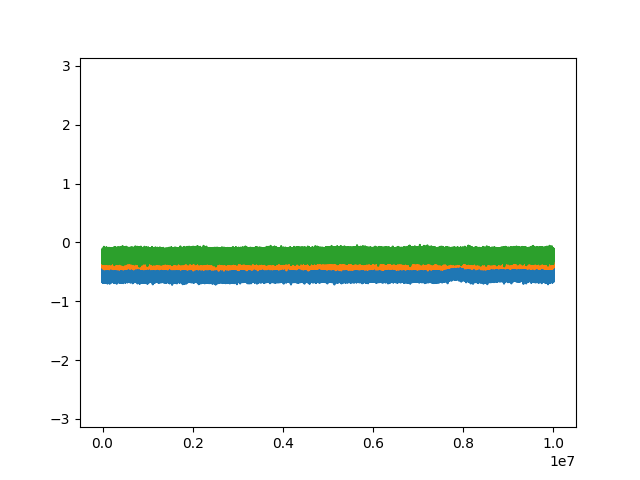

In [15]:
%matplotlib widget
plt.close('all')
plt.figure()
start_ref = int(10e7)
stop_ref = int(11e7)
phi_init_0 = (np.angle(received_sig[0,start_ref:stop_ref]/received_sig[1,start_ref:stop_ref]))
phi_init_1 = (np.angle(received_sig[0,start_ref:stop_ref]/received_sig[2,start_ref:stop_ref]))
phi_init_2 = (np.angle(received_sig[2,start_ref:stop_ref]/received_sig[1,start_ref:stop_ref]))

# plt.plot(np.angle(received_sig[0,0:int(1e3)]))
plt.plot(phi_init_0)
plt.plot(phi_init_1)
plt.plot(phi_init_2)

plt.ylim([-np.pi, np.pi])
# plt.show()

In [16]:
plt.title('Phase differences - after 10e7 samples')
plt.legend(['rx0/rx2', 'rx1/rx2', 'rx0/rx1'])
plt.ylabel('Phase difference (rad)')
# plt.xlabel('Sample number')
# plt.savefig('phase_diff_reffff.png')

Text(36.685183899270164, 0.5, 'Phase difference (rad)')